# Task 01 · Data Cleaning & Preprocessing

IncodeVision Data Science Internship. Titanic dataset: from raw data to a clean, model-ready CSV.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

BASE = Path.cwd()
RAW = BASE / "data" / "titanic_raw.csv"
OUT = BASE / "outputs"
OUT.mkdir(exist_ok=True)
log = []

def note(msg):
    print(msg)
    log.append(msg)

## 1. Load & inspect

Raw shape: (891, 15)
Missing values before:
age            177
embarked         2
deck           688
embark_town      2
Duplicate rows before: 107


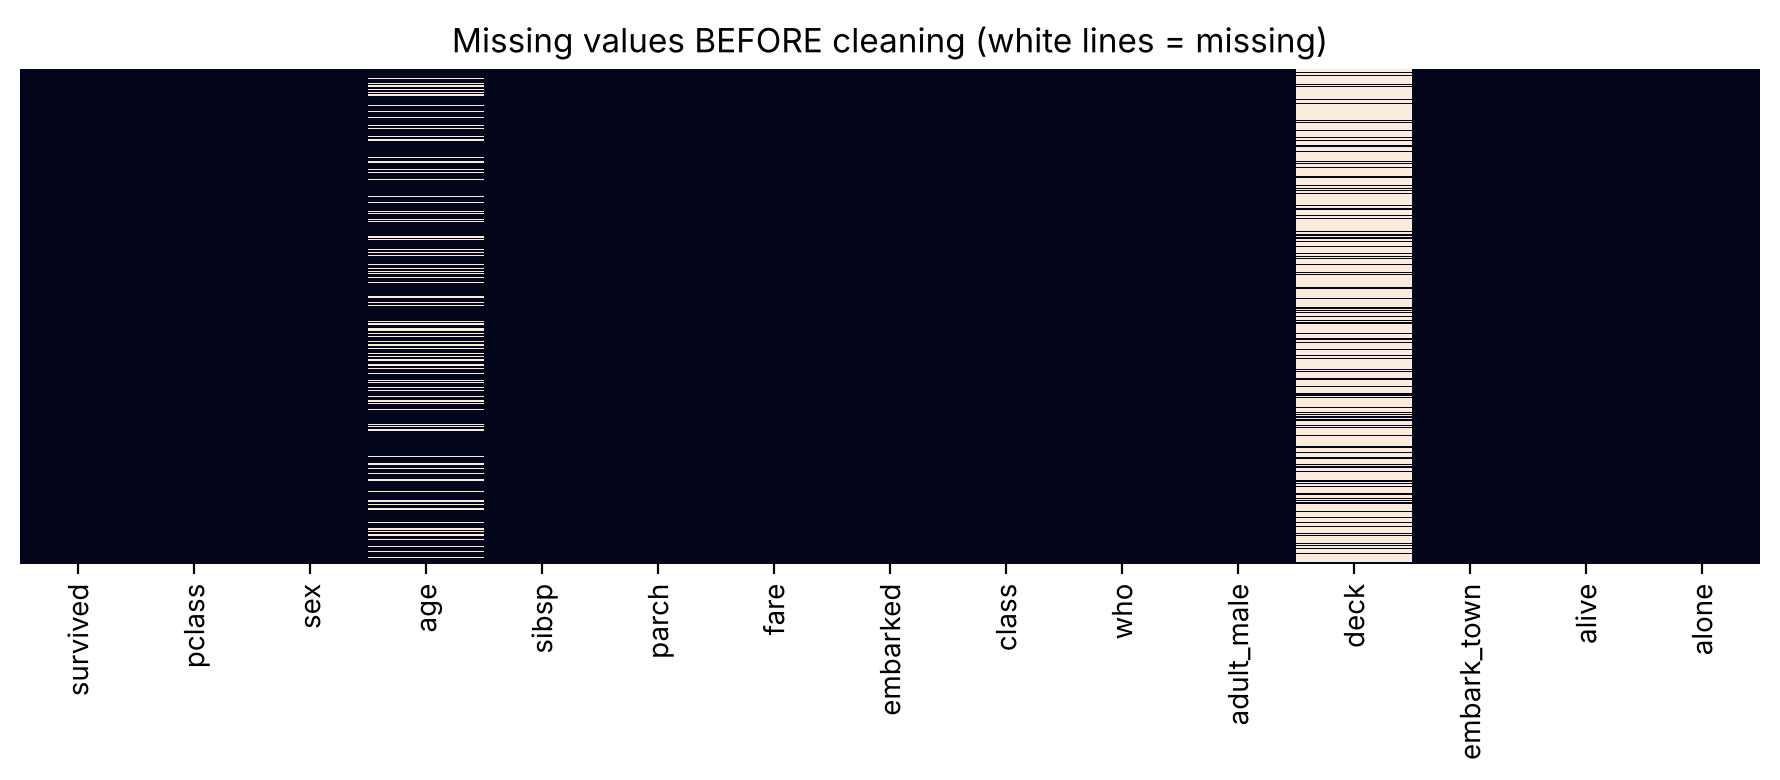

In [2]:
df = pd.read_csv(RAW)
note(f"Raw shape: {df.shape}")
missing_before = df.isna().sum()
missing_before = missing_before[missing_before > 0]
note(f"Missing values before:\n{missing_before.to_string()}")
note(f"Duplicate rows before: {df.duplicated().sum()}")

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=ax)
ax.set_title("Missing values BEFORE cleaning (white lines = missing)")
fig.tight_layout(); fig.savefig(OUT / "01_missing_before.png", dpi=130); plt.show()

## 2. Remove duplicates

In [3]:
n = len(df)
df = df.drop_duplicates().reset_index(drop=True)
note(f"Removed {n - len(df)} duplicate rows -> {df.shape}")

Removed 107 duplicate rows -> (784, 15)


## 3. Fix inconsistent text (strip + consistent case)

In [4]:
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].astype("string").str.strip()
for c in ["sex", "who", "alive"]:
    df[c] = df[c].str.lower()
for c in ["class", "embark_town"]:
    df[c] = df[c].str.title()
df["embarked"] = df["embarked"].str.upper()

## 4. Redundant columns

In [5]:
# 'alive' duplicates 'survived'; 'class' duplicates 'pclass'; 'embark_town' duplicates 'embarked'
df = df.drop(columns=["alive", "class", "embark_town"])
note("Dropped redundant columns: alive, class, embark_town")

Dropped redundant columns: alive, class, embark_town


## 5. Missing values

In [6]:
# deck: ~77% missing -> not reliable; keep as 'Unknown' category instead of guessing
df["deck"] = df["deck"].fillna("Unknown")
# embarked: 2 missing -> mode
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
# age: median by passenger class and sex (better than one global median)
df["age"] = df["age"].fillna(df.groupby(["pclass", "sex"])["age"].transform("median"))
note(f"Missing values after treatment: {int(df.isna().sum().sum())}")

Missing values after treatment: 0


## 6. Data types

In [7]:
df["survived"] = df["survived"].astype("int8")
df["pclass"] = df["pclass"].astype("int8")
df["adult_male"] = df["adult_male"].astype(bool)
df["alone"] = df["alone"].astype(bool)
for c in ["sex", "embarked", "who", "deck"]:
    df[c] = df[c].astype("category")
df["age"] = df["age"].round(1)

## 7. Outliers (IQR rule, capping = winsorizing)

fare: 102 outliers outside [-31.0, 73.2] -> capped
age: 15 outliers outside [-2.0, 62.0] -> capped


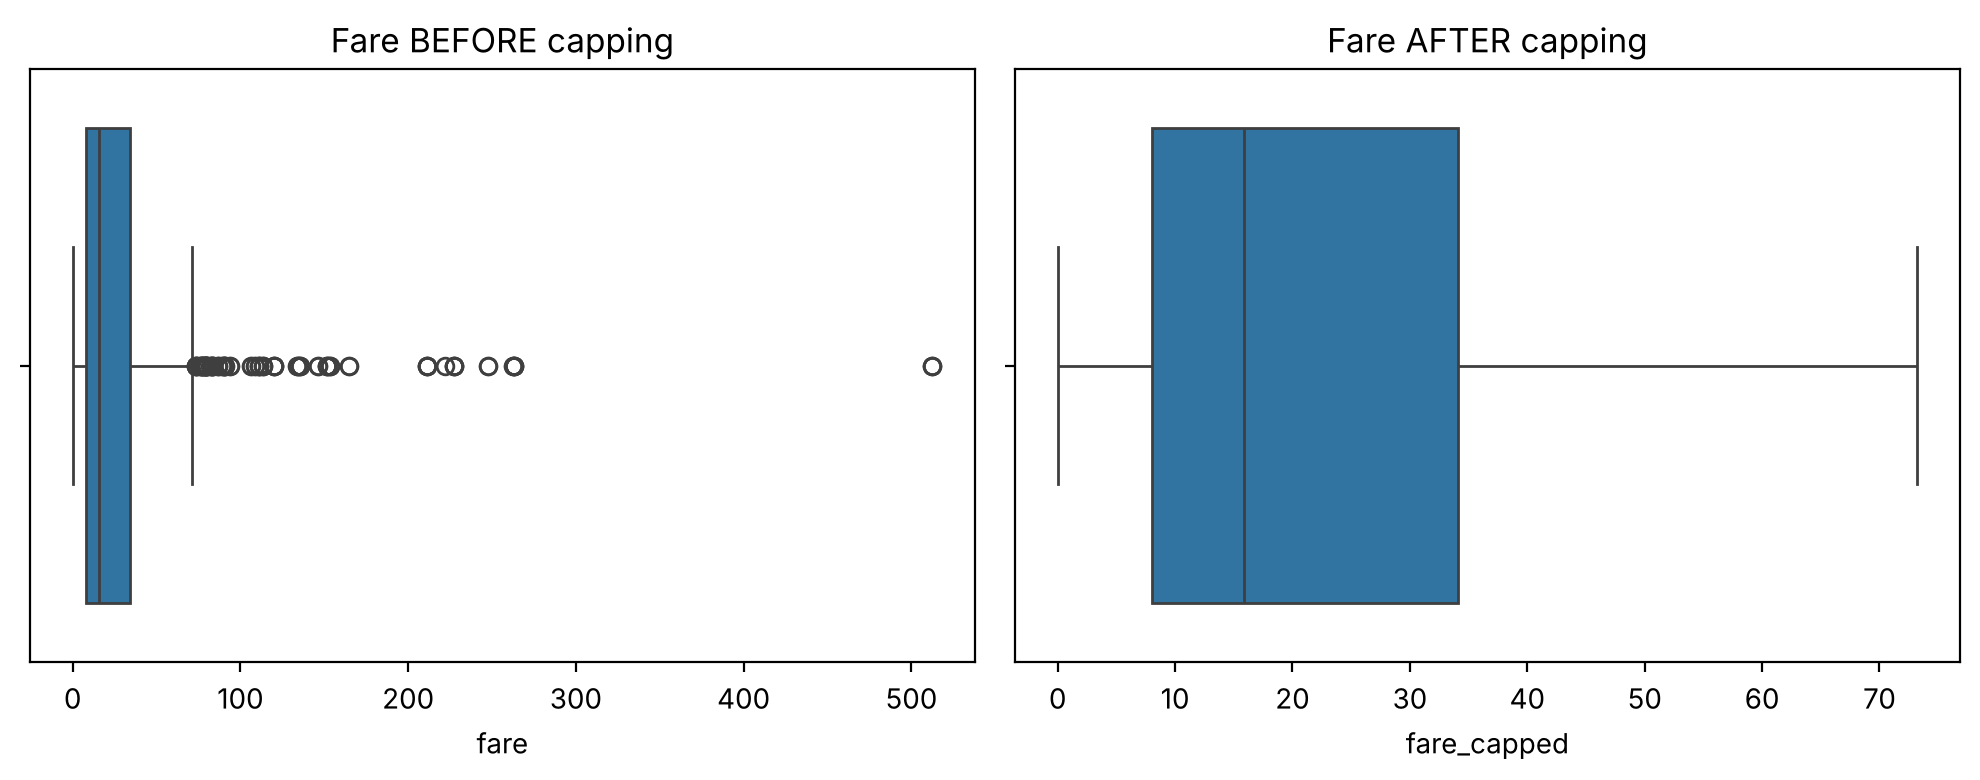

In [8]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x=df["fare"], ax=axes[0]); axes[0].set_title("Fare BEFORE capping")
for col in ["fare", "age"]:
    lo, hi = iqr_bounds(df[col])
    n_out = int(((df[col] < lo) | (df[col] > hi)).sum())
    note(f"{col}: {n_out} outliers outside [{lo:.1f}, {hi:.1f}] -> capped")
    df[col + "_capped"] = df[col].clip(lo, hi)
sns.boxplot(x=df["fare_capped"], ax=axes[1]); axes[1].set_title("Fare AFTER capping")
fig.tight_layout(); fig.savefig(OUT / "02_outliers_fare.png", dpi=130); plt.show()

## 8. Feature engineering + encoding + scaling

In [9]:
df["family_size"] = df["sibsp"] + df["parch"] + 1
clean = df.copy()
clean.to_csv(BASE / "data" / "titanic_clean.csv", index=False)

ml = pd.get_dummies(clean.drop(columns=["age", "fare"]),
                    columns=["sex", "embarked", "who", "deck"], drop_first=True)
for c in ml.select_dtypes(bool).columns:
    ml[c] = ml[c].astype("int8")
for c in ["age_capped", "fare_capped", "family_size"]:
    ml[c + "_scaled"] = (ml[c] - ml[c].mean()) / ml[c].std()
ml.to_csv(BASE / "data" / "titanic_ml_ready.csv", index=False)

## 9. Final checks + report

Identical-looking rows created by imputation (kept, different passengers): 7
Clean shape: (784, 15) | ML-ready shape: (784, 24)


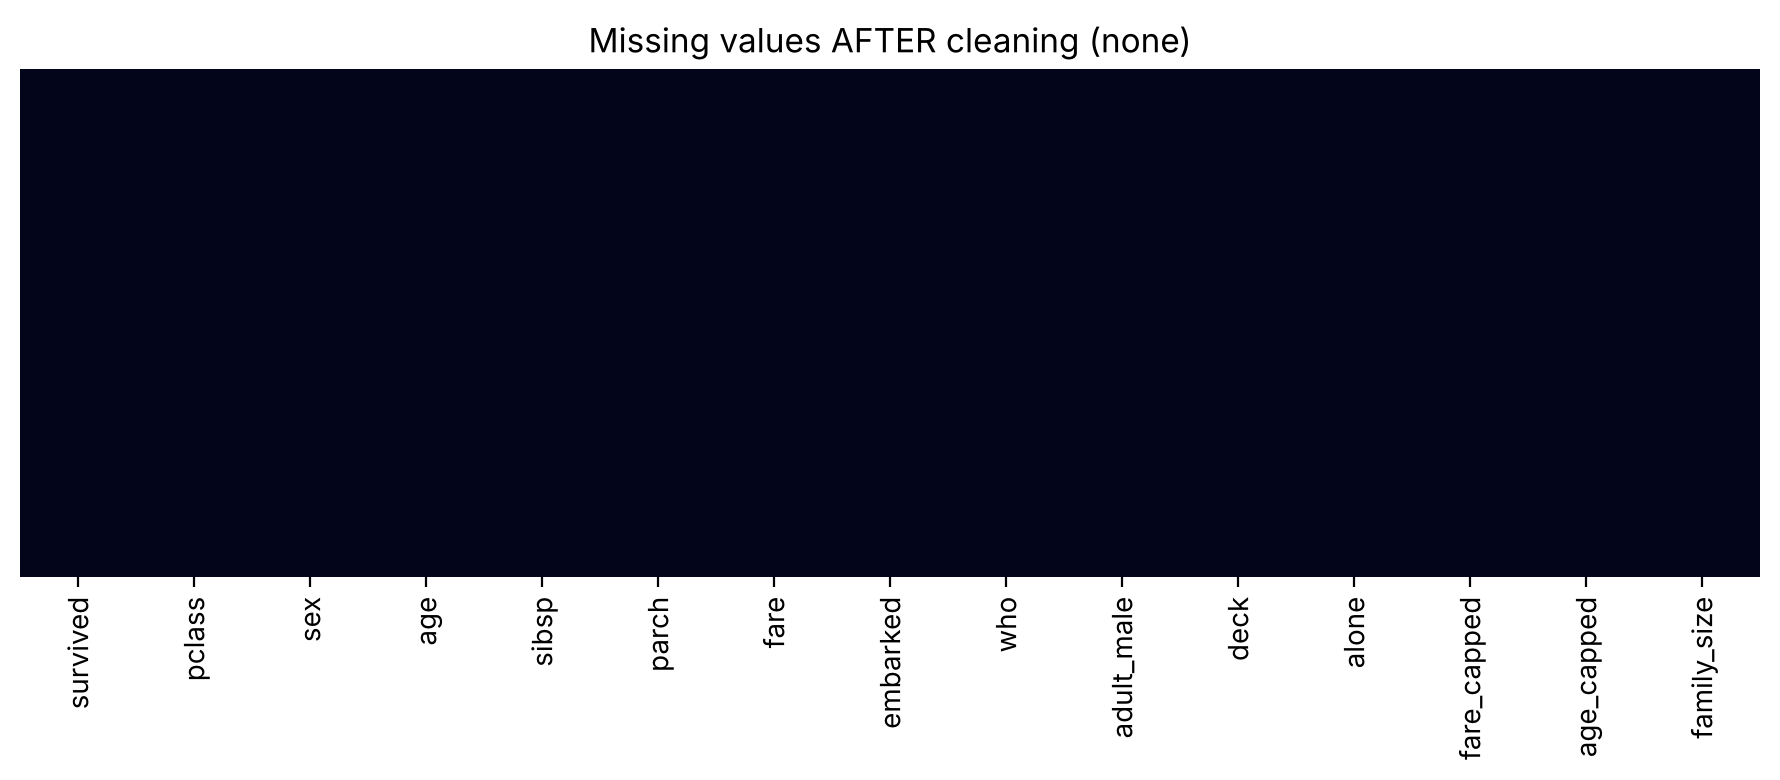

       metric  before  after_clean
         rows     891          784
      columns      15           15
   duplicates     107            0
missing cells     869            0


In [10]:
assert clean.isna().sum().sum() == 0
# Exact duplicates were removed on the RAW data (step 2). After imputing age, a few different
# passengers can look identical (the dataset has no passenger ID), so they are kept on purpose.
note(f"Identical-looking rows created by imputation (kept, different passengers): {int(clean.duplicated().sum())}")
note(f"Clean shape: {clean.shape} | ML-ready shape: {ml.shape}")

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(clean.isna(), cbar=False, yticklabels=False, ax=ax)
ax.set_title("Missing values AFTER cleaning (none)")
fig.tight_layout(); fig.savefig(OUT / "03_missing_after.png", dpi=130); plt.show()

summary = pd.DataFrame({
    "metric": ["rows", "columns", "duplicates", "missing cells"],
    "before": [891, 15, 107, int(missing_before.sum())],
    "after_clean": [len(clean), clean.shape[1], 0, 0],
})
summary.to_csv(OUT / "cleaning_summary.csv", index=False)
(OUT / "cleaning_log.txt").write_text("\n\n".join(log), encoding="utf-8")
print(summary.to_string(index=False))